**Легенда учебного проекта:**

Вы — аналитик в автодилерском холдинге. Один из автоцентров холдинга, Меркур Авто, хочет понять своё положение на рынке и выявить точки роста. Вам передали данные по всем продажам автомобилей в Казахстане за девять месяцев 2019 года.

Ваша задача — подготовить данные и провести анализ, который поможет менеджменту Меркур Авто оценить свою эффективность и принять стратегические решения.

---

## Введение

**Входящий запрос**:
> - Довести датасет до состояния, пригодного для анализа. Создать скрипт его очистки для автоматизации обработки похожих данных в будущем.
> - Провести разведочный анализ (EDA) всего рынка и дать оценку позиции и ключевым показателям эффективности автоцентра Меркур Авто.

**Этапы работы**:
- Загрузка и первичный осмотр данных
- Глубокая очистка и преобразование данных
- Исследовательский анализ данных (EDA)
- Анализ рынка и позиции Меркур Авто
- Выводы

## Загрузка данных

In [1]:
import pandas as pd

#Plotly Express для визуализации графиков
import plotly.express as px

#Обычная десятичная запись чисел в таблицах
pd.set_option('display.float_format', lambda value: f'{value:,.2f}'.replace(',', ' '))

In [2]:
data = pd.read_csv('autokz2019.csv', sep=';', decimal=',')

### Очистка данных

In [3]:
display(
    pd.DataFrame({
    "column":  data.columns,
    "dtype":   data.dtypes.astype(str).values,
    "total":   len(data),
    "null":    data.isna().sum().values,
    "null_%":  (data.isna().mean() * 100).round(2).values,
}).set_index("column").sort_values("null_%", ascending=False)
)

,dtype,total,null,null_%
column,,,,
Форма расчета,object,39966,25928,64.88
Тип клиента,object,39966,7047,17.63
Сегмент,object,39966,6761,16.92
Тип привода,object,39966,4289,10.73
"Объём двиг, л,",object,39966,4258,10.65
Модификация,object,39966,3591,8.99
Коробка передач,object,39966,3255,8.14
Вид топлива,object,39966,3140,7.86
Год выпуска,object,39966,501,1.25


Главная таблица состоит из почти ~40 тыс. строк, при этом большинство колонок — это категориальные и строчные значения. Предварительно видно, что наиболее неполная колонка — это форма расчета: ~65% значений в ней не заполнено. Тип клиента и сегмент имеют ~17% пропусков, в типе привода около 11% пропусков.

In [4]:
df = data.dropna(how="all").drop_duplicates().reset_index(drop=True)

#По заданию есть конкретный список колонок для удаления, но их наименование не совсем совпадает с датасетом. Удалены наиболее близкие
df = df.drop(columns=["Наименование дилерского центра", "Локализация производства", "Тип клиента", "Модификация","Форма расчета"])

df = df.rename(columns={
    "Год": "year", "Месяц": "month", "Компания": "company",
    "Бренд": "brand", "Модель": "model", "Год выпуска": "year_prod",
    "Страна-производитель": "COO", "Вид топлива": "type_fuel",
    "Объём двиг, л,": "volume_engine", "Коробка передач": "trans",
    "Тип привода": "type_drive", "Сегмент": "segment", "Регион": "region",
    "Количество": "amount", "Цена, USD": "price_usd",
    "Продажа, USD": "sell_usd", "Область": "area", "Сегментация 2013": "segment_2013",
    "Класс 2013": "class_2013", "Сегментация Eng": "segment_eng"
})

display(pd.DataFrame({
    "column": df.columns, "dtype": df.dtypes.astype(str).values, "total": len(df),
    "null": df.isna().sum().values, "null_%": (df.isna().mean() * 100).round(2).values
}).set_index("column").sort_values("null_%", ascending=False))

,dtype,total,null,null_%
column,,,,
segment,object,21268,4580,21.53
volume_engine,object,21268,2292,10.78
type_drive,object,21268,2221,10.44
type_fuel,object,21268,1887,8.87
trans,object,21268,1880,8.84
year_prod,object,21268,233,1.10
amount,float64,21268,6,0.03
class_2013,object,21268,0,0.00
segment_2013,object,21268,0,0.00


Удалено 18 698 полных совпадений, осталось 21 268 строк. Полным совпадением считается, если записи полностью одинаковые, т.к разницу между ними нужно было бы определять через id сделки, но такой информации нет.

## Глубокая очистка и преобразование данных

На этом этапе будет работа над страной производства, видом топлива, типом привода и типом трансмиссии - колонки будут перекодированы в понятный формат. Далее осуществляется проверка числовых столбцов и поиск аномалий, а также дата продажи будет выведена в отельный столбец.

Затем будет проверка неявных дубликатов и очистка данных в названиях компании и объёме двигателя.

Все работы будут выполняться по принципу: сначала посмотреть данные, затем принять решение.

### Страна производства

In [5]:
display(df['COO'].value_counts())

COO
Республика Казахстан    10453
Российская Федерация     6574
Япония                   2559
Турция                    449
Таиланд                   392
США                       257
Германия                  252
UK                        179
Австрия                    33
Узбекистан                 30
Китай                      22
Корея                      16
Швеция                     16
Нидерланды                 12
Испания                     9
Польша                      6
Бельгия                     6
Венгрия                     2
Белоруссия                  1
Name: count, dtype: int64

В столбце представлены 19 названий стран, перекодировка будет в словарь ALPHA-3: каждое исходное название должно иметь соответствующий код.

In [6]:
country_codes = {
    'Республика Казахстан': 'KAZ', 'Российская Федерация': 'RUS', 'Япония': 'JPN',
    'Турция': 'TUR', 'Таиланд': 'THA', 'США': 'USA', 'Германия': 'DEU', 'UK': 'GBR',
    'Китай': 'CHN', 'Узбекистан': 'UZB', 'Австрия': 'AUT', 'Швеция': 'SWE',
    'Корея': 'KOR', 'Нидерланды': 'NLD', 'Испания': 'ESP', 'Польша': 'POL',
    'Бельгия': 'BEL', 'Венгрия': 'HUN', 'Белоруссия': 'BLR'
}

df['COO'] = df['COO'].str.strip().map(country_codes)
display(df['COO'].value_counts())

COO
KAZ    10453
RUS     6574
JPN     2559
TUR      449
THA      392
USA      257
DEU      252
GBR      179
AUT       33
UZB       30
CHN       22
KOR       16
SWE       16
NLD       12
ESP        9
POL        6
BEL        6
HUN        2
BLR        1
Name: count, dtype: int64

### Вид топлива

In [7]:
display(df['type_fuel'].value_counts())

type_fuel
Бензин           18618
Дизель             644
бензин              66
2                   16
1,6                 11
гибрид              10
дизель               9
0                    3
Электро              3
Электричество        1
Name: count, dtype: int64

Бензин и дизель записаны в разном регистре, а электро выглядит как неявный дубликат.

2, 1, 6 - может относиться и к бензину, и к дизелю. 0 - может быть намеренным значением для неизвестного параметра. По этим причинам для таких видов топлива замена по кодам производиться не будет.

In [8]:
fuel_codes = {
    'бензин': 'F',
    'дизель': 'D',
    'электро': 'E',
    'электричество': 'E',
    'гибрид': 'HYB'
}

df['type_fuel'] = df['type_fuel'].str.strip().str.lower().map(fuel_codes)
display(df['type_fuel'].value_counts())

type_fuel
F      18684
D        653
HYB       10
E          4
Name: count, dtype: int64

### Тип привода

In [9]:
display(df['type_drive'].value_counts())

type_drive
4WD              5095
Передний         2938
2 WD             2485
2WD              1822
Полный           1728
4 WD             1229
Задний           1114
FF               1036
AWD               643
FWD               543
RWD               178
0                  68
передний           51
quattro            43
4Motion            25
Передний (FF)      10
4х2.2              10
4x4                 5
полный              5
4x2                 4
4х4                 4
#Н/Д                3
4х2                 2
4X2                 2
Астана              2
4X4                 2
Name: count, dtype: int64

Есть неявные дубликаты, когда один и тот же привод указан разными способами. Например, AWD, 4WD, Полный, quattro и 4Motion - это всё полный привод. 
FF и Передний можно привести в FWD, Задний и RWD — в RWD. Для 2WD и 4×2 оставим общий код 2WD, как наиболее близкий вариант. 

Остальное останется без замен, так как однозначно привести их единому формату нельзя. Например, неясно, что такое "Астана".

In [10]:
drive_codes = {
    '4wd': '4WD', '4 wd': '4WD', 'awd': '4WD', 'полный': '4WD',
    'quattro': '4WD', '4motion': '4WD', '4x4': '4WD', '4х4': '4WD',
    'передний': 'FWD', 'передний (ff)': 'FWD', 'ff': 'FWD', 'fwd': 'FWD',
    'задний': 'RWD', 'rwd': 'RWD', '2wd': '2WD', '2 wd': '2WD', '4x2': '2WD', '4х2': '2WD'
}

df['type_drive'] = df['type_drive'].str.strip().str.lower().map(drive_codes)
display(df['type_drive'].value_counts(dropna=False))

type_drive
4WD    8779
FWD    4578
2WD    4315
NaN    2304
RWD    1292
Name: count, dtype: int64

### Числовые столбцы и аномалии

In [11]:
print('Годы выпуска:', df['year_prod'].unique())
display(df[['amount', 'price_usd', 'sell_usd']].describe())

Годы выпуска: ['2018' '2017' '2019' nan '2016' '2014' '2013' '2011' '2\xa0018'
 '2\xa0019']


,amount,price_usd,sell_usd
count,21 262.00,21 268.00,21 268.00
mean,1.65,27 994.54,38 328.93
std,3.22,21 279.08,66 977.41
min,-1.00,7 100.00,-35 588.25
25%,1.00,14 886.30,16 559.44
50%,1.00,20 700.00,25 235.92
75%,1.00,32 380.85,41 311.10
max,115.00,328 510.97,3 778 206.26


В годе выпуска одновременно есть строки `2019` и `2\xa0019`. У количества минимум −1 и максимум 115, а отрицательное число продаж это выглядит странно. 

In [12]:
# Убираем пробелы из года выпуска и переводим его в целое число
year_text = df['year_prod'].astype('string').str.replace(r'\s+', '', regex=True)
df['year_prod'] = pd.to_numeric(year_text, errors='coerce').astype('Int64')

display(df['year_prod'].value_counts(dropna=False).sort_index())

year_prod
2011        1
2013        1
2014        2
2016       29
2017      190
2018     5650
2019    15162
<NA>      233
Name: count, dtype: Int64

In [13]:
for column in ['price_usd', 'amount', 'sell_usd']:
    df[column] = pd.to_numeric(
        df[column].astype('string').str.replace(r'\s+', '', regex=True).str.replace(',', '.', regex=False),
        errors='coerce'
    )

df['amount'] = df['amount'].astype('Int64')

display(df.loc[df['amount'].isna() | df['amount'].lt(0) | df['amount'].ge(50),
               ['brand', 'model', 'amount', 'price_usd', 'sell_usd']])

print('Строк без количества:', df['amount'].isna().sum())
print('Расхождений цена-количество:',
      ((df['price_usd'] * df['amount'] - df['sell_usd']).abs() > 0.02).sum())

display(df[['price_usd', 'amount', 'sell_usd']].dtypes)

,brand,model,amount,price_usd,sell_usd
7341,Jac,S3,70,15 613.95,1 092 976.75
8288,Kia,Rio,63,13 500.00,850 500.00
8352,Kia,Rio,60,13 500.00,810 000.00
8726,Kia,Sportage,<NA>,20 700.00,0.00
8843,Lada,4x4,54,9 000.00,486 000.00
8870,Lada,4x4,115,9 000.00,1 035 000.00
8953,Lada,4x4,66,9 000.00,594 000.00
9016,Lada,Granta,50,8 700.00,435 000.00
9087,Lada,Granta,50,7 100.00,355 000.00
9178,Lada,Granta,50,7 100.00,355 000.00


Строк без количества: 6
Расхождений цена-количество: 0


price_usd    Float64
amount         Int64
sell_usd     Float64
dtype: object

Количество −1 у Skoda Superb сопровождается отрицательной выручкой — скорее всего возврат, строку не требуется удалять. Партия 100 Skoda Octavia согласована с ценой и итоговой суммой, так что это может быть оптовой поставкой. Также есть и 115 Lada 4x4, где выручка также сходится, значит тоже, вероятно, оптовая поставка.

У шести строк не указано количество, выручка равна нулю. Возможно ошибка, а может и нет - из таблицы строки не будут удалены, но и в расчёте продаж учитываться не будут. 

### Дата продажи

In [14]:
display(df[['year', 'month']].drop_duplicates())

,year,month
0,2019,Май
1,2019,Август
2,2019,Апрель
3,2019,Июль
5,2019,Февраль
7,2019,Июнь
12,2019,Сентябрь
14,2019,Январь
21,2019,Март


В файле указан 2019 год, а месяцы записаны словами. День сделки неизвестен, поэтому датой продажи будет последний день месяца.

Исходные столбцы с годом и месяцем будут удалены.

In [15]:
months = {'Январь': 1, 'Февраль': 2, 'Март': 3, 'Апрель': 4, 'Май': 5,
          'Июнь': 6, 'Июль': 7, 'Август': 8, 'Сентябрь': 9}

df['Дата продажи'] = pd.to_datetime(pd.DataFrame({
    'year': df['year'], 'month': df['month'].map(months), 'day': 1
})) + pd.offsets.MonthEnd(0)

df = df.drop(columns=['year', 'month'])

display(df['Дата продажи'].drop_duplicates().sort_values().reset_index(drop=True))

0   2019-01-31
1   2019-02-28
2   2019-03-31
3   2019-04-30
4   2019-05-31
5   2019-06-30
6   2019-07-31
7   2019-08-31
8   2019-09-30
Name: Дата продажи, dtype: datetime64[ns]

### Название компании

In [16]:
pd.DataFrame(sorted(df["company"].unique()))

,0
0,Allur Auto
1,Almaty Motors Premium
2,Astana Motors
3,Astana Motors
4,Autokapital
5,Caspian Motors
6,Daewoo Bus Kazakhstan
7,Eurasia Motor Premium
8,Hino Motors
9,Hyundai Com Trans Kazakhstan


По списку видны дубликаты - Astana Motors и Astana Motors с пробелом в конце строки, Mercur Auto и Mercur Autos, а также русские и английские варианты одних названий. Явные соответствия будут объединены, а вот похожие названия без очевидного соответствия, например, разные компании Автомир, объединяться не будут.

In [17]:
df['company'] = df['company'].str.strip().replace({
    'Mercur Auto': 'Меркур Авто', 'Mercur Autos': 'Меркур Авто',
    'Каспиан Моторс': 'Caspian Motors', 'Автокапитал': 'Autokapital',
    'MMC RUS': 'ММС Рус', 'Равон Моторс Казахстан': 'Ravon Motors Kazakhstan',
    'Ravon Motors Kazakstan': 'Ravon Motors Kazakhstan',
    'Хино Моторс Казахстан': 'Hino Motors Kazakhstan', 'Hino Motors': 'Hino Motors Kazakhstan'
})

print('Уникальных компаний:', df['company'].nunique())

Уникальных компаний: 33


В исходном наборе было 40 вариантов названий компаний, после удаления пробелов и объединения русских и английских вариантов осталось 33. Mercur Auto и Mercur Autos теперь учитываются как одна компания — Меркур Авто.

### Объём двигателя

In [18]:
volume_counts = df['volume_engine'].value_counts()
display(volume_counts.head(10))

# Отдельно проверка литеры L, по заданию не очент ясно как оно выглядит
with_liters = volume_counts.index.str.contains(' L', case=False, na=False)
display(volume_counts[with_liters].head())

volume_engine
2          3100
1,6        2554
2,7        2078
1,596      1117
1,6 MPI    1082
2,5         792
2,0 MPI     711
1,774       535
2.5         531
2.0         473
Name: count, dtype: int64

volume_engine
8,4 L,     1
4,98 L,    1
3,0 L      1
Name: count, dtype: int64

In [19]:
#Строки, где вместо литров указаны другие единицы
wrong_units = df['volume_engine'].str.contains(r'л\.с\.|kwh', case=False, na=False)
display(df.loc[wrong_units, ['brand', 'model', 'type_fuel', 'volume_engine']].drop_duplicates())

,brand,model,type_fuel,volume_engine
21134,Jaguar,I-Pace,E,400 Л.С.
21231,ANKAI,HFF6124G03EV3,E,88 KWH


В объёме есть десятичные запятые и технические пометки, например 1,6 MPI и 4,98 L,. Из таких значений выделим число. 400 Л.С. у Jaguar I-Pace и 88 KWH у ANKAI обозначают мощность и ёмкость батареи. Объём двигателя в этих строках оставим пустым.

In [20]:
#По заданию исправляем аномалии для Chevrolet Niva (21.6, 20.6 и т. д.).
niva_values = pd.to_numeric(
    df.loc[df['brand'].eq('Chevrolet') & df['model'].eq('Niva'), 'volume_engine']
      .str.replace(',', '.', regex=False), errors='coerce'
)
display(niva_values.value_counts().sort_index().to_frame('Строк'))

,Строк
volume_engine,
1.70,254
2.70,1
3.70,1
4.70,1
5.70,1
6.70,1
7.70,1
8.70,1
9.70,1


У Chevrolet Niva 254 строки содержат 1,7 л. Остальные 25 строк образуют последовательность от 2,7 до 26,7 л с шагом 1. Исправим их по наиболее частому значению этой же модели в файле.

In [21]:
# Исправляем записи в столбце объёма двигателя
engine_text = df['volume_engine'].str.strip().str.replace(',', '.', regex=False)

df['volume_engine'] = pd.to_numeric(
    engine_text.str.extract(r'^(\d+(?:\.\d+)?)', expand=False), errors='coerce'
)
df.loc[wrong_units | df['volume_engine'].le(0), 'volume_engine'] = float('nan')

niva = df['brand'].eq('Chevrolet') & df['model'].eq('Niva')
niva_bad = niva & df['volume_engine'].gt(2)
df.loc[niva_bad, 'volume_engine'] = niva_values.mode().iloc[0]

display(df.loc[niva, 'volume_engine'].value_counts())
print('Строк с мощностью или ёмкостью вместо объёма:', wrong_units.sum())

volume_engine
1.70    279
Name: count, dtype: int64

Строк с мощностью или ёмкостью вместо объёма: 4


### Регион и область

In [22]:
geography = df[['region', 'area']].drop_duplicates()
display(geography.sort_values(['region', 'area']).reset_index(drop=True))
print('Регионов:', df['region'].nunique())

,region,area
0,Актау,Мангистауская область
1,Актобе,Актюбинская область
2,Алматы,г.Алматы
3,Атырау,Атырауская область
4,Зыряновск,Восточно-Казахстанская область
5,Караганда,Карагандинская область
6,Каскелен,Алматинская область
7,Кокшетау,Акмолинская область
8,Костанай,Костанайская область
9,Кульсары,Атырауская область


Регионов: 26


Регион и область записаны в разном регистре. Например, ЭКСПОРТ записан заглавными буквами, а в Кызылординская область второе слово начинается со строчной. Приведём каждое слово к заглавной букве и добавим пробел после сокращения города.

In [23]:
for column in ['region', 'area']:
    df[column] = df[column].str.strip().str.replace(r'\.(?=\S)', '. ', regex=True).str.title()
    df[column] = df[column].str.replace(r'^Г\.', 'г.', regex=True)

print('Регионы:', df['region'].nunique())
geography_clean = df[['region', 'area']].drop_duplicates()
display(geography_clean.sort_values(['region', 'area']).reset_index(drop=True))

Регионы: 26


,region,area
0,Актау,Мангистауская Область
1,Актобе,Актюбинская Область
2,Алматы,г. Алматы
3,Атырау,Атырауская Область
4,Зыряновск,Восточно-Казахстанская Область
5,Караганда,Карагандинская Область
6,Каскелен,Алматинская Область
7,Кокшетау,Акмолинская Область
8,Костанай,Костанайская Область
9,Кульсары,Атырауская Область


### Тип трансмиссии

In [24]:
#Вывод посложнее, иначе ноутбук срезает список и не показывает все строки
with pd.option_context('display.max_rows', None):
    display(df['trans'].value_counts())

trans
AT                    4423
6 AT                  4328
Мех.                  1506
MT                    1504
CVT                   1183
5МТ                    993
CVT (вариатор)         690
6AT                    653
5 МТ                   617
AMT                    395
6АТ                    378
5MT                    363
6 АТ                   348
АКПП                   226
4АТ                    133
АКП                    121
CVT(вAриATор)          120
8AT                    119
4 АТ                   104
6MT                     86
7DSG                    86
6 MT                    75
9G-TRONIC               72
CVT (вариATор)          70
6DSG                    69
8АТ                     45
7 DSG                   41
DSG                     38
8 АТ                    34
МТ                      34
МКПП                    33
6 DSG                   29
Tiptronic               28
АТ                      25
6А                      25
6A                      23
АT                    

В коробке передач есть разные обозначения одного типа, например AT и АТ, MT и МТ. Вариаторы, роботы и редукторы будут считаться как Автомат.

Остальное выпускается и как механика, и как автомат, поэтому остаются вне категории.

In [25]:
transmission = df['trans'].str.strip().str.lower()

automatic_codes = [
    'at', 'ат', 'аt', 'a/t', 'а/t', 'amt', 'акп', 'акпп', 'редуктор',
    '4at', '4ат', '4 ат', '5at', '5 at', '5ат',
    '6at', '6 at', '6ат', '6 ат', '6a', '6а', '7at', '7ат',
    '7 акп', '7акп', '7 акпп (pdk)', '7 акпп pdk',
    '8at', '8 at', '8ат', '8 ат', '8a', '8акпп', '8-ступ акпп',
    '8 акпп (pdk)', '8 акпп tiptronic s', '9at', '12at', '12ат',
    'cvt', 'cvt (вариатор)', 'cvt (вариatор)', 'cvt(вaриatор)',
    'dsg', '6dsg', '6 dsg', '7dsg', '7 dsg', 'dct', '7dct', '7 dct',
    'pdk', 'powershift s6', 's-tronic', 'steptronic', 'tiptronic',
    '7g-tronic', '9g-tronic'
]

manual_codes = [
    'mt', 'мт', 'мt', 'm/t', 'м/t', 'мех.', 'мкп', 'мкпп',
    '5m', '5м', '5mt', '5мт', '5 мт',
    '6mt', '6 mt', '6мт', '6 мт', '6m/t'
]

# Сначала оставляем тип пустым, затем заполняем по спискам
transmission_type = pd.Series(pd.NA, index=df.index, dtype='string')
transmission_type.loc[transmission.isin(automatic_codes)] = 'Автомат'
transmission_type.loc[transmission.isin(manual_codes)] = 'Механика'

print('Обозначения без определённого типа:')
display(df.loc[transmission_type.isna(), 'trans'].value_counts())

df['trans'] = transmission_type
display(df['trans'].value_counts(dropna=False))

Обозначения без определённого типа:


trans
4WD         21
8            5
Передний     3
0            3
#Н/Д         3
TDI          3
Name: count, dtype: int64

trans
Автомат     14040
Механика     5310
<NA>         1918
Name: count, dtype: Int64

### Финальные преобразования типов

In [26]:
categories = ['type_fuel', 'trans', 'type_drive', 'segment_2013', 'class_2013']
df['Дата продажи'] = pd.to_datetime(df['Дата продажи'])
df[categories] = df[categories].astype('category')

display(df[['Дата продажи', *categories]].dtypes)

Дата продажи    datetime64[ns]
type_fuel             category
trans                 category
type_drive            category
segment_2013          category
class_2013            category
dtype: object

In [27]:
# Сохраняем очищенные данные в CSV
df.to_csv(
    'autokz2019_clean.csv',
    sep=';', index=False, date_format='%Y-%m-%d'
)
print('Очищенные данные сохранены в autokz2019_clean.csv')

Очищенные данные сохранены в autokz2019_clean.csv


## Исследовательский анализ данных (EDA)

Продажи будут посчитаны по сумме amount, а не по количеству строк, так как одна запись может говорить о продаже несколько машин. Держим в уме, что возврат уменьшает итоговые продажи и выручку.

Отдельно выделим экспорт, т.к это всё-таки внешний рынок, а не внутренний.

Кроме суммы продаж также посмотрим средний чек по формуле: **sell_usd.sum() / amount.sum()**.

In [28]:
#Строки, где количество машин больше 0
sales = df.loc[df['amount'].notna() & df['amount'].ne(0)]
is_export = sales['region'].eq('Экспорт')

#Внутренний рынок с учётом возвратов
sales_kz = sales.loc[~is_export].copy()

#Для распределений берём внутренние продажи без возвратов
sales_no_returns = sales_kz.loc[sales_kz['amount'].gt(0)]

print('Продажи на внутреннем рынке, шт.:', sales_kz['amount'].sum())
print('Экспорт, шт.:', sales.loc[is_export, 'amount'].sum())

Продажи на внутреннем рынке, шт.: 34725
Экспорт, шт.: 440


### Цена, объём двигателя и год выпуска

In [29]:
display(sales_kz[['price_usd', 'volume_engine', 'year_prod', 'amount', 'sell_usd']].describe().round(2))

,price_usd,volume_engine,year_prod,amount,sell_usd
count,20 931.00,18 669.00,20 703.00,20 931.00,20 931.00
mean,27 880.17,2.28,2 018.71,1.66,38 301.94
std,21 164.85,0.93,0.49,3.21,66 946.54
min,7 100.00,1.20,2 011.00,-1.00,-35 588.25
25%,14 897.45,1.60,2 018.00,1.00,16 578.70
50%,20 700.00,2.00,2 019.00,1.00,25 198.94
75%,32 246.09,2.70,2 019.00,1.00,41 311.10
max,328 510.97,13.00,2 019.00,115.00,3 778 206.26


Цена колеблется от 7,100 до 328,511 USD, при этом медиана — 20,700 USD. Медианный год выпуска автомобиля (year_prod) — 2019. 

Далее будет рассмотрено распределение цен автомобилей, а также сколько машин было продано в каждом году.

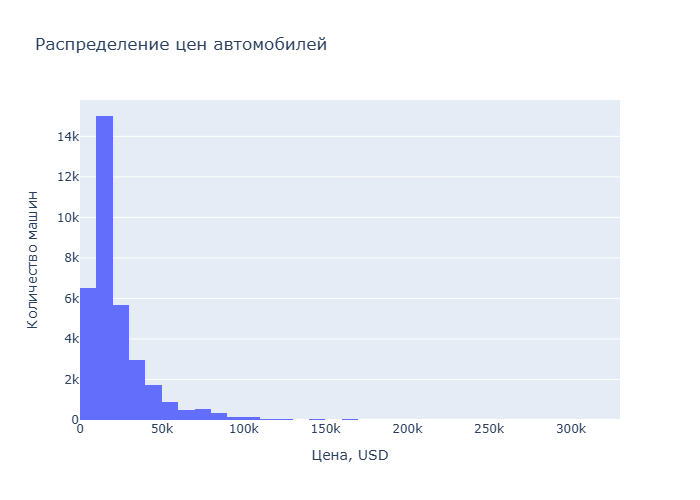

In [30]:
fig = px.histogram(sales_no_returns, x='price_usd', y='amount', histfunc='sum', nbins=40,
                   title='Распределение цен автомобилей',
                   labels={'price_usd': 'Цена, USD', 'amount': 'Количество машин'})
fig.update_layout(yaxis_title='Количество машин')
fig.show(renderer='png')

Основная часть продаж находится в нижней и средней части ценового диапазона; распределение имеет длинный правый хвост. Наиболее частая цена продажи приходится на 10-20К USD, на втором месте популярны машины до 10К USd, а на третьем - 20-30К USD.

In [31]:
year_sales = sales_no_returns.groupby('year_prod')['amount'].sum().sort_index()
display(year_sales.to_frame('Продано машин'))

,Продано машин
year_prod,
2011,1
2013,1
2014,2
2016,29
2017,206
2018,7258
2019,26340


Подавляющее число машин продано с выпуском от 2019 года, а также наблюдается явная тенденция - чем старее автомобиль, тем реже его покупают. Ожидаемо, что 2011 и 2013 год выпуска являются самыми непопулярными с точки зрения продаж.

### Продажи по брендам и моделям

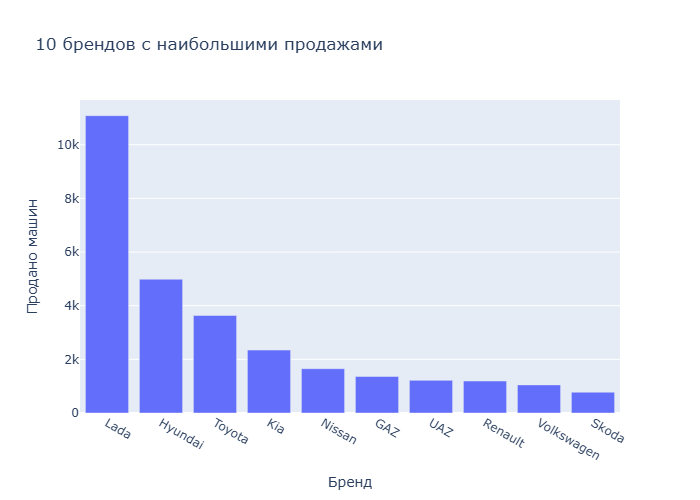

Всего продано машин на внутреннем рынке: 34725


In [32]:
brand_sales = sales_kz.groupby('brand')['amount'].sum().sort_values(ascending=False)

fig = px.bar(brand_sales.head(10).rename('amount').reset_index(), x='brand', y='amount',
             title='10 брендов с наибольшими продажами',
             labels={'brand': 'Бренд', 'amount': 'Продано машин'})
fig.show(renderer='png')

print('Всего продано машин на внутреннем рынке:', sales_kz['amount'].sum())

По количеству машин лидирует Lada — 11,085, или 31.9% рынка. В целом, на первые три бренда приходится свыше половины продаж - 56,8%.

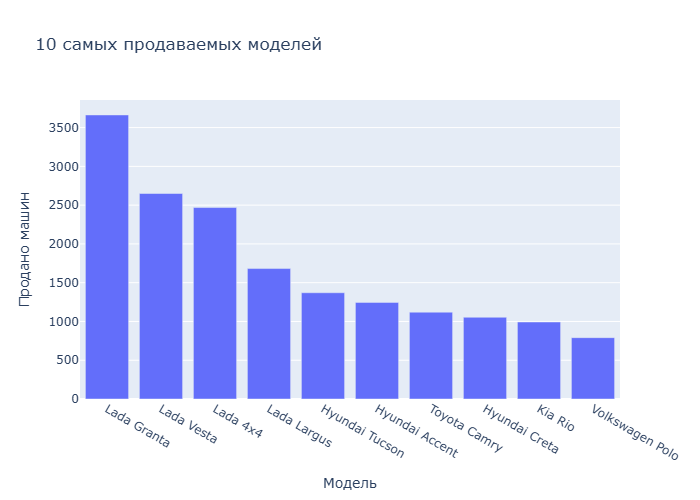

In [33]:
model_sales = sales_kz.groupby(['brand', 'model'])['amount'].sum().sort_values(ascending=False).head(10).reset_index()
model_sales['name'] = model_sales['brand'] + ' ' + model_sales['model']
fig = px.bar(model_sales, x='name', y='amount', title='10 самых продаваемых моделей',
             labels={'name': 'Модель', 'amount': 'Продано машин'})
fig.show(renderer='png')

Ожидаемо, что если Lada наиболее продаваемый бренд, то и в моделях сохраняется лидерство. Самая продаваемая модель — Lada Granta: 3,663 машин.

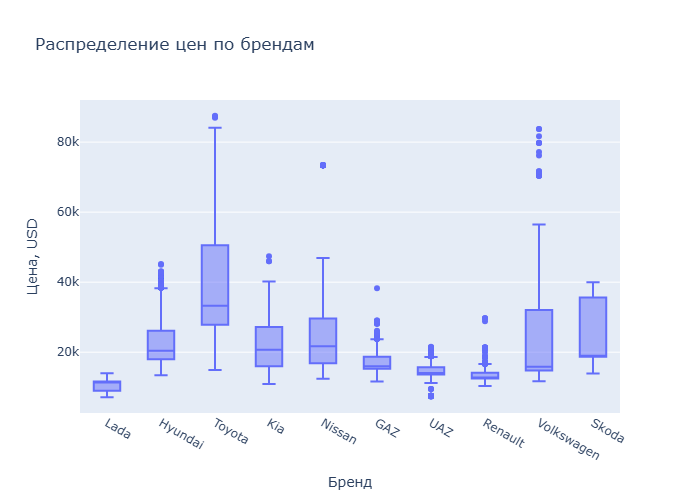

In [34]:
brand_prices = sales_no_returns[['brand', 'price_usd']].dropna()
top_brands = brand_sales.head(10).index.tolist()

fig = px.box(brand_prices.loc[brand_prices['brand'].isin(top_brands)],
             x='brand', y='price_usd', category_orders={'brand': top_brands},
             title='Распределение цен по брендам',
             labels={'brand': 'Бренд', 'price_usd': 'Цена, USD'})
fig.show(renderer='png')

Теперь видно, что Lada хоть и является самой продаваемой моделью, находится в довольно низком ценовом сегменте. Это может быть одной из причин её популярности.

А самый большой разброс цен у Toyota, бренд охватывает цены от 14,9К USD до 87,5К USD.

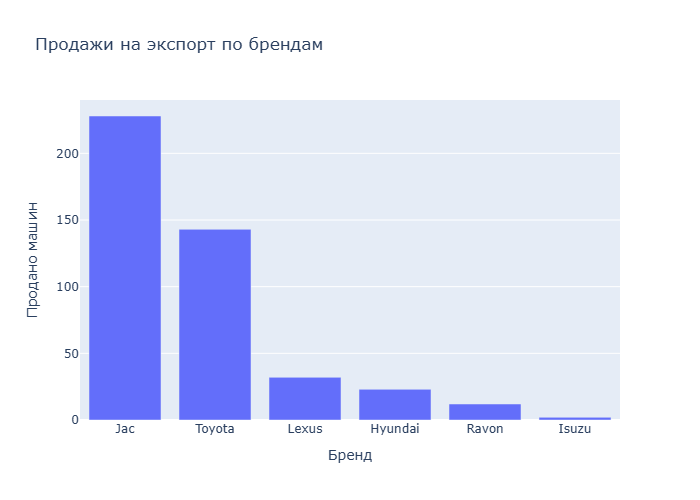

Всего экспортировано машин: 440


In [35]:
export_by_brand = sales.loc[is_export].groupby('brand')['amount'].sum().sort_values(ascending=False)

fig = px.bar(export_by_brand.rename('amount').reset_index(), x='brand', y='amount',
             title='Продажи на экспорт по брендам',
             labels={'brand': 'Бренд', 'amount': 'Продано машин'})
fig.show(renderer='png')

print('Всего экспортировано машин:', export_by_brand.sum())

Если смотреть на продажи внешнего рынка, то здесь уже лидирует Jac - 51,8% проданных машин. 

Интересно обстоят дела с Toyota - их было продано 32,5% на экспорт и 10,5% на внутреннем рынке. То есть это тот бренд, который хорошо себя чувствует в обеих сферах, в то время как Hyandai - хоть и занимает долю внутреннего рынка, на экспорте уже значительно уступает.

### Продажи по регионам

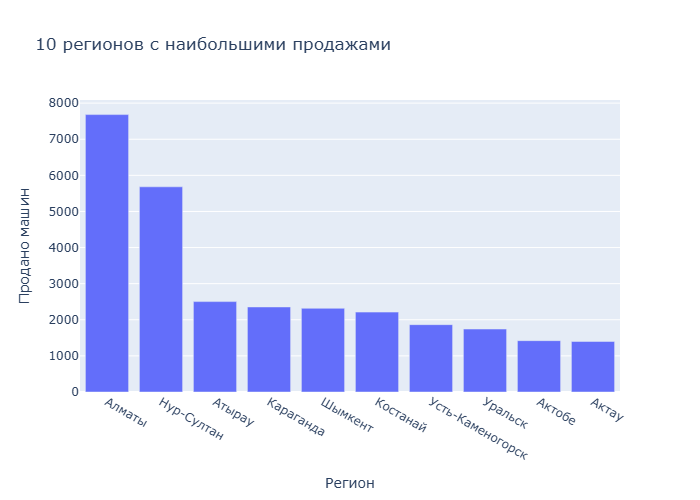

Всего продано машин на внутреннем рынке: 34725


In [36]:
region_sales = sales_kz.groupby('region')['amount'].sum().sort_values(ascending=False)
fig = px.bar(region_sales.head(10).rename('amount').reset_index(), x='region', y='amount',
             title='10 регионов с наибольшими продажами',
             labels={'region': 'Регион', 'amount': 'Продано машин'})
fig.show(renderer='png')

print('Всего продано машин на внутреннем рынке:', sales_kz['amount'].sum())

Больше всего машин продано в регионе Алматы — 7 682 (22,1% рынка). Неудивительно, так как это самый крупнонаселённый город Казахстана.
На втором месте столица - Нур-Султан, где продано 5 682 машины.

На первые три региона приходится 45,7% продаж - это значит, что основные продажи происходят в крупных городах.

Из 440 экспортированных машин 228 пришлось на Jac и 143 на Toyota. Вместе эти два бренда дали 84,3% экспорта.

### Продажи по видам топлива

In [37]:
fuel_sales = sales_kz.groupby('type_fuel', observed=True, dropna=False)['amount'].sum().to_frame('Продано машин')
fuel_sales['Доля, %'] = (fuel_sales['Продано машин'] / sales_kz['amount'].sum() * 100).round(2)
display(fuel_sales)

,Продано машин,"Доля, %"
type_fuel,,
D,903,2.60
E,4,0.01
F,30822,88.76
HYB,10,0.03
NaN,2986,8.60


Бензин (F) предпочитают чаще - 88,8% продаж, в то время как дизель (D) — 2,6%. 

На электрические и гибридные автомобили вместе приходится около 0,04%.

### Продажи по коробкам передач

In [38]:
trans_sales = sales_kz.groupby('trans', observed=True, dropna=False)['amount'].sum().to_frame('Продано машин')
trans_sales['Доля, %'] = (trans_sales['Продано машин'] / sales_kz['amount'].sum() * 100).round(2)
display(trans_sales)

,Продано машин,"Доля, %"
trans,,
Автомат,17845,51.39
Механика,13892,40.01
<NA>,2988,8.60


По коробкам передач предпочтения клиентов склоняются, скорее, к автоматическим коробкам - 51,4% продаж. У механических — 40,01%.

### Продажи по объёму двигателя

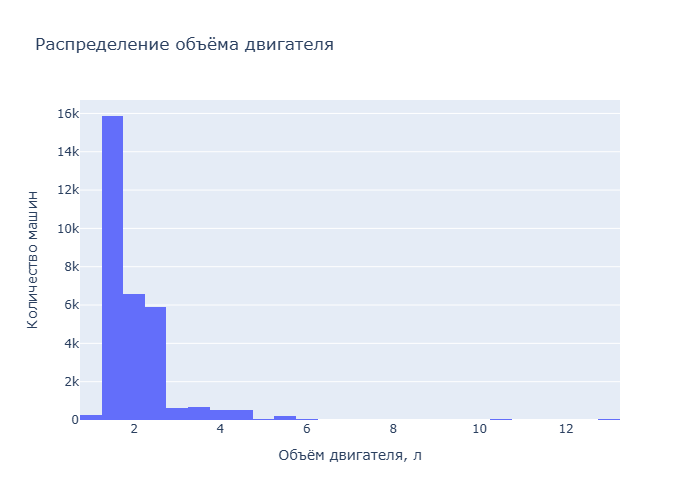

In [39]:
fig = px.histogram(sales_no_returns.dropna(subset=['volume_engine']), x='volume_engine',
                   y='amount', histfunc='sum', nbins=30, title='Распределение объёма двигателя',
                   labels={'volume_engine': 'Объём двигателя, л', 'amount': 'Количество машин'})
fig.update_layout(yaxis_title='Количество машин')
fig.show(renderer='png')

Самый частый объём по количеству машин находится в диапазоне 1,25 - 1,749 л.

Можно оценить, есть связь объёма двигателя с ценой?

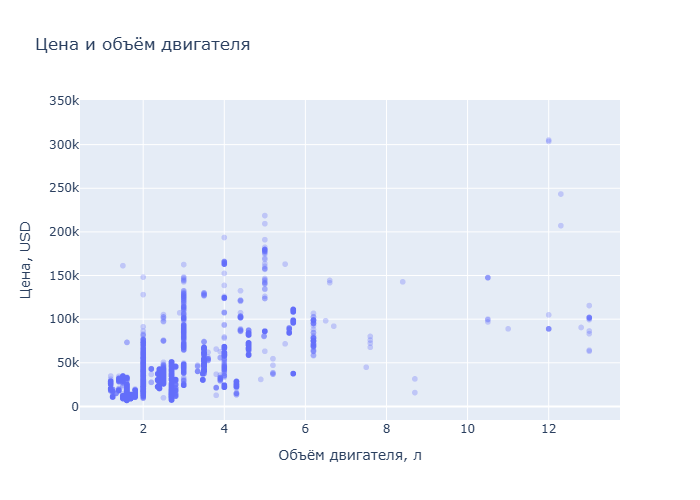

Корреляция по строкам: 0.72


In [40]:
fig = px.scatter(sales_no_returns, x='volume_engine', y='price_usd', opacity=0.3,
                 hover_data=['brand', 'model'], title='Цена и объём двигателя',
                 labels={'volume_engine': 'Объём двигателя, л', 'price_usd': 'Цена, USD'})
fig.show(renderer='png')
print('Корреляция по строкам:', round(sales_no_returns['price_usd'].corr(sales_no_returns['volume_engine']), 2))

Между ценой и объёмом двигателя наблюдается положительная связь: корреляция по строкам — 0,72. В среднем машины с более крупным двигателем дороже, но при одном объёме разброс цен остаётся большим.

### Аномалии цен

Самые важные аномалии - в цене, поэтому имеет смысл сделать несколько срезов и посмотреть, где максимум выше порогового значения.

Пороговое значение определяется так: вычисляется 25 персентиль и 75 персентиль. Это ширина диапазона цены, которая наиболее частая. Затем добавляем ещё полторы ширины диапазона, чтобы получить запас - это нужно для того, чтобы не считать аномалиями очень высокие цены, которые могли бы быть обычными для какой-то группы. Например, премиальные автомобили с учётом запаса не попадут в аномалии.

In [41]:
prices = sales_kz['price_usd']
q1 = prices.quantile(0.25)
q3 = prices.quantile(0.75)
price_limit = q3 + 1.5 * (q3 - q1)

print('Пороговое значение, USD:', round(price_limit, 2))

groups = [
    ('Бренд', ['brand']),
    ('Модель', ['brand', 'model']),
    ('Объём двигателя', ['volume_engine']),
    ('Регион', ['region'])
]

for title, columns in groups:
    group_prices = sales_kz.groupby(columns)['price_usd'].agg(['max', 'median', 'count'])
    top3 = group_prices.loc[group_prices['max'] > price_limit].nlargest(3, 'max')
    top3 = top3.rename(columns={'max': 'Максимум, USD', 'median': 'Медиана, USD', 'count': 'Записей'})
    print(f'\n{title}')
    print(top3.round(2).to_string())

Пороговое значение, USD: 58269.05

Бренд
                      Максимум, USD  Медиана, USD  Записей
brand                                                     
Mercedes-Benz Trucks     328 510.97     54 685.72       24
ANKAI                    307 986.36     81 707.54       67
Hyundai Truck & Bus      243 388.74     32 634.99       89

Модель
                                    Максимум, USD  Медиана, USD  Записей
brand                model                                              
Mercedes-Benz Trucks Setra             328 510.97    328 510.97        1
ANKAI                HFF6124G03EV3     307 986.36    307 986.36        1
Mercedes-Benz Trucks Tourismo          305 252.02    304 451.45        2

Объём двигателя
               Максимум, USD  Медиана, USD  Записей
volume_engine                                      
12.00             305 252.02     88 913.89        7
12.30             243 388.74    225 268.68        2
5.00              218 681.74    142 329.50       57

Регион
      

Премиальные модели оказались сильно дороже рынка, поэтому даже запас в полторы ширины диапазона оказался недостаточен. В любом случае, касаемо моделей - это не аномалии: Mercedes-Benz Trucks действительно премиум-сегмент, а HFF6124G03EV3 - электробус.

По остальным записям видно, что они не единичны - значит это вряд ли ошибка. Скорее всего, это действительно реалистичные продажи и не аномалии.


Что касается общих трендов: 

- Почти каждая третья проданная машина — Lada, а примерно девять из десяти — бензиновые.
- Наибольшее число продаж продаж приходится на 2 крупных города Казахстана: Алматы и Нур-Султан.
- Чаще покупают машины текущего года выпуска, а чем машина старше - тем реже её удаётся продать.

Из интересных особенностей:

- Самая высокая цена — около 329 тыс. USD у Setra. Это премиальный автомобиль
- По количеству проданных автомобилей выделяются партии из 115 Lada 4×4 и 100 Skoda Octavia

## Анализ рынка и позиции Меркур Авто
### Доля рынка и средний чек

### Доля рынка

In [42]:
mercur = sales_kz.loc[sales_kz['company'].eq('Меркур Авто')]
print('Меркур Авто и внутренний рынок:', round(mercur['amount'].sum()))

print('Доля Меркур Авто в штуках, %:',
      round(mercur['amount'].sum() / sales_kz['amount'].sum() * 100, 2))
print('Доля Меркур Авто в выручке, %:',
      round(mercur['sell_usd'].sum() / sales_kz['sell_usd'].sum() * 100, 2))

mercur_export = sales.loc[is_export & sales['company'].eq('Меркур Авто')]
print('Меркур Авто и экспорт:', mercur_export['amount'].sum(), 'машин')

Меркур Авто и внутренний рынок: 394
Доля Меркур Авто в штуках, %: 1.13
Доля Меркур Авто в выручке, %: 1.89
Меркур Авто и экспорт: 0 машин


Меркур Авто работает только на внутренний рынок Казахстана, поэтому далее экспорт не рассматривается и сравнение производится только для Казахстана. Компания продала 394 автомобиля, что в общей доле внутреннего рынка является довольно маленькой долей и составляет 1,13% продаж в штуках и 1,89% в выручке.

### Доля в разрезе брендов

In [43]:
brand_position = pd.DataFrame({
    'Рынок, шт.': sales_kz.groupby('brand')['amount'].sum(),
    'Меркур Авто, шт.': mercur.groupby('brand')['amount'].sum()
}).fillna(0)

brand_position = brand_position.loc[brand_position['Меркур Авто, шт.'].gt(0)]
brand_position['Доля Меркур Авто, %'] = brand_position['Меркур Авто, шт.'] / brand_position['Рынок, шт.'] * 100
brand_position['Структура Меркур Авто, %'] = brand_position['Меркур Авто, шт.'] / mercur['amount'].sum() * 100

display(brand_position.round(2))

,"Рынок, шт.","Меркур Авто, шт.","Доля Меркур Авто, %","Структура Меркур Авто, %"
brand,,,,
Audi,48,48,100.00,12.18
Porsche,52,52,100.00,13.20
Volkswagen,1048,294,28.05,74.62


Часто продаваемым брендом являются Audi, Porsche и Volkswagen. 

Volkswagen приносит 74.6% продаж компании, а доля Меркур Авто внутри продаж бренда Volkswagen — 28.1%.

Все продажи Audi и Porsche в этом наборе относятся к Меркур Авто, поэтому наблюдаемая доля по этим брендам — 100%. Однако, это означает, что Меркур Авто является единственным поставщиком по данным в выборке, но не означает монополию на рынке среди продаж автомобилей.

### Доля в разрезе регионов

In [44]:
region_position = pd.DataFrame({
    'Рынок, шт.': sales_kz.groupby('region')['amount'].sum(),
    'Меркур Авто, шт.': mercur.groupby('region')['amount'].sum()
}).fillna(0)

region_position['Доля Меркур Авто, %'] = region_position['Меркур Авто, шт.'] / region_position['Рынок, шт.'] * 100
region_position['Структура Меркур Авто, %'] = region_position['Меркур Авто, шт.'] / mercur['amount'].sum() * 100

display(region_position.sort_values('Меркур Авто, шт.', ascending=False).round(2))

,"Рынок, шт.","Меркур Авто, шт.","Доля Меркур Авто, %","Структура Меркур Авто, %"
region,,,,
Алматы,7682,251,3.27,63.71
Нур-Султан,5682,51,0.90,12.94
Атырау,2503,43,1.72,10.91
Караганда,2355,21,0.89,5.33
Уральск,1743,14,0.80,3.55
Костанай,2212,14,0.63,3.55
Актау,1400,0,0.00,0.00
Рудный,21,0,0.00,0.00
Шымкент,2318,0,0.00,0.00


Главный регион продаж для компании — Алматы: 251 машин и 63,7% её продаж. Доля Меркур Авто в этом регионе — 3.27%. 

Интересно, что в 19 регионах внутреннего рынка отсутствуют какие-либо продажи компании. Это может быть намеренным решением, а может быть риском того, что в случае изменения спроса в крупнейших городах - компания потеряет значительную долю продаж.

### Доля в разрезе сегментов

Для расчёта берём segment_2013. Этот столбец заполнен во всех строках, а в исходном segment есть пропуски и значения вроде названий дилеров.

In [45]:
segment_position = pd.DataFrame({
    'Рынок, шт.': sales_kz.groupby('segment_2013', observed=True)['amount'].sum(),
    'Меркур Авто, шт.': mercur.groupby('segment_2013', observed=True)['amount'].sum()
}).fillna(0)
segment_position['Доля Меркур Авто, %'] = segment_position['Меркур Авто, шт.'] / segment_position['Рынок, шт.'] * 100
segment_position['Структура рынка, %'] = segment_position['Рынок, шт.'] / sales_kz['amount'].sum() * 100
segment_position['Структура Меркур Авто, %'] = segment_position['Меркур Авто, шт.'] / mercur['amount'].sum() * 100
display(segment_position.round(2))

,"Рынок, шт.","Меркур Авто, шт.","Доля Меркур Авто, %","Структура рынка, %","Структура Меркур Авто, %"
segment_2013,,,,,
Внедорожники,14047,145,1.03,40.45,36.80
Коммерческие автомобили,3487,8,0.23,10.04,2.03
Легковые автомобили,15008,234,1.56,43.22,59.39
Минивэны,1798,5,0.28,5.18,1.27
Пикапы,385,2,0.52,1.11,0.51


Легковые автомобили составляют 59,4% продаж Меркур Авто — 234 из 394 машин. 

1,56% — это доля Меркур Авто среди всех продаж легковых автомобилей на внутреннем рынке.

### Сравнение среднего чека и структуры продаж

Средний чек считаем как выручку на один проданный автомобиль с учётом возврата.

In [46]:
comparison = pd.DataFrame({
    'Рынок': [sales_kz['amount'].sum(), sales_kz['sell_usd'].sum()],
    'Меркур Авто': [mercur['amount'].sum(), mercur['sell_usd'].sum()]
}, index=['Продано машин', 'Выручка, USD'])

comparison.loc['Средний чек, USD'] = comparison.loc['Выручка, USD'] / comparison.loc['Продано машин']

display(comparison.round(2))

,Рынок,Меркур Авто
Продано машин,34 725.00,394.00
"Выручка, USD",801 697 865.97,15 121 529.04
"Средний чек, USD",23 087.05,38 379.52


Средний чек Меркур Авто составил 38 380 USD против 23 087 USD по рынку. Разница заметная, и в пользу компании, скорее всего, играет выбор брендов - продажи Audi и Porsche, где Меркур Авто является единственным в выборке данных.

Но факт того, что средний чек Меркур Авто выше среднего чека по рынку - это сильная сторона компании.

### Ближайшие конкуренты

Ближайшими конкурентами Меркур Авто считаются компании, которые продавали машины того же бренда и класса в том же регионе.

In [47]:
match_columns = ['brand', 'class_2013', 'region']
mercur_groups = mercur.loc[mercur['amount'].gt(0), match_columns].drop_duplicates()
other_sales = sales_no_returns.loc[sales_no_returns['company'].ne('Меркур Авто')]

competitor_sales = other_sales.merge(mercur_groups, on=match_columns)
competitor_totals = competitor_sales.groupby('company')['amount'].sum().sort_values(ascending=False)
competitor_table = competitor_sales.pivot_table(
    index='company', columns='brand', values='amount', aggfunc='sum', fill_value=0
)

competitor_table = competitor_table.loc[competitor_totals.index]
competitor_table.loc['Всего'] = competitor_table.sum()
display(competitor_table)

brand,Volkswagen
company,
Volkswagen Group Rus,635
Автодом Motors KST,49
Автомир-Центр,33
"ТОО ""Eurasia Motor Zhaik""",15
Всего,732


Нашлись четыре компании-конкурента, а основным по числу проданных машин в совпадающих группах является компания Volkswagen Group Rus — 635.

In [48]:
almaty_vw = sales_no_returns.loc[
    sales_no_returns['brand'].eq('Volkswagen')
    & sales_no_returns['region'].eq('Алматы')
]
almaty_comparison = almaty_vw.pivot_table(
    index='segment_2013', columns='company', values='amount',
    aggfunc='sum', fill_value=0, observed=True
)
almaty_comparison.loc['Всего, шт.'] = almaty_comparison.sum()
display(almaty_comparison)

company,Volkswagen Group Rus,Меркур Авто
segment_2013,,
Внедорожники,9,37
Коммерческие автомобили,6,7
Легковые автомобили,221,114
Минивэны,2,3
Пикапы,3,0
"Всего, шт.",241,161


Volkswagen Group Rus продала 241 автомобиль Volkswagen, а Меркур Авто — 161. У обеих компаний больше всего продаж в сегменте легковых автомобилей.

Таким образом, Меркур Авто находится в не очень выгодном положении - для него и бренд, и город являются основным источником выручки, но при этом именно там наиболее сильный конкурент, который при этом чувствует себя лучше по продажам в большинстве сегментов автомобилей. Уступает конкурент в категории внедорожников, но Меркур Авто на них сосредоточен в меньшей степени.

### Сильные и слабые стороны

По долям видно, что компания сильно зависит от Volkswagen, продажи которого составляют основной объём выручки. Можно посмотреть, как менялись продажи брендов по месяцам.

In [49]:
mercur_month = mercur.pivot_table(index='Дата продажи', columns='brand', values='amount', aggfunc='sum', fill_value=0)
mercur_month['Выручка за месяц, USD'] = mercur.groupby('Дата продажи')['sell_usd'].sum()
display(mercur_month)

brand,Audi,Porsche,Volkswagen,"Выручка за месяц, USD"
Дата продажи,,,,
2019-01-31,2,1,55,1 430 299.93
2019-02-28,2,5,86,2 415 248.12
2019-03-31,9,7,46,2 383 403.86
2019-04-30,4,8,56,2 414 052.74
2019-05-31,7,8,51,2 351 547.35
2019-06-30,3,5,0,756 811.00
2019-07-31,9,7,0,1 307 886.00
2019-08-31,6,7,0,1 031 434.04
2019-09-30,6,4,0,1 030 846.00


Volkswagen действительно сильно влияет на Меркур Авто. Продажи бренда закончились в июне и, начиная с этого месяца, заметно упала общая выручка. Такую зависимость стоит отнести к слабой стороне позиционирования.

#### Продажи по регионам и месяцам

In [50]:
mercur_month_regions = mercur.pivot_table(
    index='Дата продажи', columns='region', values='amount', aggfunc='sum', fill_value=0
)
mercur_month_regions['Выручка за месяц, USD'] = mercur_month['Выручка за месяц, USD']
display(mercur_month_regions)

region,Алматы,Атырау,Караганда,Костанай,Нур-Султан,Уральск,"Выручка за месяц, USD"
Дата продажи,,,,,,,
2019-01-31,40,5,0,2,11,0,1 430 299.93
2019-02-28,40,8,16,2,18,9,2 415 248.12
2019-03-31,29,12,5,8,4,4,2 383 403.86
2019-04-30,46,8,0,1,12,1,2 414 052.74
2019-05-31,54,10,0,1,1,0,2 351 547.35
2019-06-30,8,0,0,0,0,0,756 811.00
2019-07-31,14,0,0,0,2,0,1 307 886.00
2019-08-31,11,0,0,0,2,0,1 031 434.04
2019-09-30,9,0,0,0,1,0,1 030 846.00


Регион продажи также сильно влияет на Меркур Авто, начиная с июня количество продаж в некоторых городах стало нулевым. 

#### Продажи Меркур Авто по месяцам, регионам и брендам

In [51]:
mercur_region_brand = mercur.pivot_table(
    index=['Дата продажи', 'brand'], columns='region', values='amount', aggfunc='sum', fill_value=0
)
display(mercur_region_brand)

region                   Алматы  Атырау  Караганда  Костанай  Нур-Султан  \
Дата продажи brand                                                         
2019-01-31   Audi             2       0          0         0           0   
             Porsche          1       0          0         0           0   
             Volkswagen      37       5          0         2          11   
2019-02-28   Audi             1       0          0         0           1   
             Porsche          5       0          0         0           0   
             Volkswagen      34       8         16         2          17   
2019-03-31   Audi             8       0          0         0           1   
             Porsche          7       0          0         0           0   
             Volkswagen      14      12          5         8           3   
2019-04-30   Audi             3       0          0         1           0   
             Porsche          8       0          0         0           0   
             Volkswagen      35       8          0         0          12   
2019-05-31   Audi             5       0          0         1           1   
             Porsche          8       0          0         0           0   
             Volkswagen      41      10          0         0           0   
2019-06-30   Audi             3       0          0         0           0   
             Porsche          5       0          0         0           0   
2019-07-31   Audi             8       0          0         0           1   
             Porsche          6       0          0         0           1   
2019-08-31   Audi             4       0          0         0           2   
             Porsche          7       0          0         0           0   
2019-09-30   Audi             5       0          0         0           1   
             Porsche          4       0          0         0           0   

region                   Уральск  
Дата продажи brand                
2019-01-31   Audi              0  
             Porsche           0  
             Volkswagen        0  
2019-02-28   Audi              0  
             Porsche           0  
             Volkswagen        9  
2019-03-31   Audi              0  
             Porsche           0  
             Volkswagen        4  
2019-04-30   Audi              0  
             Porsche           0  
             Volkswagen        1  
2019-05-31   Audi              0  
             Porsche           0  
             Volkswagen        0  
2019-06-30   Audi              0  
             Porsche           0  
2019-07-31   Audi              0  
             Porsche           0  
2019-08-31   Audi              0  
             Porsche           0  
2019-09-30   Audi              0  
             Porsche           0

Возможно, Меркур Авто стоит подробнее изучить спрос в регионах - это поможет сократить операционные расходы, в том числе затраты на логистику и оснащение.

Например, за весь 2019 год Porsche был продан в Алмате, но практически никогда - в других городах (была единственная продажа в Нур-Султане в июле). При этом по стандартам Porsche для каждой марки требуется оборудование отдельного зала со своим фирменным дизайном, а это значит, что 8 из 9 месяцев зал был в рабочем состоянии и не привлёк ни одного покупателя.

В Атырау, Караганде и Уральске покупали только Volkswagen, но никогда не покупали другие бренды.

## Итоги исследования

**Кратко о данных**

Датасет охватывает период менее 12 месяцев, а также имеет некорректные данные. Поэтому проведена очистка, после которой осталось 21 268 строк из 39 966. Также удалены полные совпадения и приведены к единому виду названия компаний и характеристики автомобилей. При подсчёте продаж возврат и крупные партии учитываются как реальные сделки, а не как аномалии.


**Общие результаты исследования**

За январь — сентябрь 2019 года на внутреннем рынке по данным выгрузки было продано 34 725 машин, а на экспорт — 440. На внутреннем рынке лидируют Lada (31,9% продаж) среди брендов, Lada Granta среди моделей и Алматы среди регионов. Бензиновые машины составляют 88,8% продаж. Самая дорогая цена за автомобиль составила 328 511 USD у модели Setra, что заметно выше общего ценового порога.

Экспорт составляет сравнительно маленькую долю, но тем не менее есть свой лидер - Jac (51,8% проданных машин). 

Также стоит отметить Toyota - их было продано 32,5% на экспорт и 10,5% на внутреннем рынке. То есть это тот бренд, который хорошо себя показывает в обоих случаях.

**Исследование Меркур Авто**

Меркур Авто совершил продажу 394 машин, что составляет 1,13% продаж в штуках и 1,89% выручки относительно всего рынка. Все машины проданы на внутренний рынок.

Легковые автомобили дают 59,4% продаж компании, при этом доля Меркур Авто среди всех продаж этого сегмента — всего 1,56%. 

Средняя выручка на автомобиль — 38 380 USD при 23 087 USD по рынку, это сильная сторона компании.
Вторая сильная сторона - работа с Audi (48 продаж) и Porsche (52 продажи). В датасете с этими брендами работает только Меркур Авто, но здесь нужно учесть полноту выборки - действительно ли больше никто не работает с этими брендами? Скорее всего, выборка неполная, а значит и в продаже этих брендов у Меркур Авто могут быть конкуренты.

Главная слабая сторона — концентрация на конкретном бренде и регионе. Volkswagen даёт 74,6% продаж Меркур Авто, а Алматы — 63,7%. При этом и бренд, и город являются сильной стороной конкурента Volkswagen Group Rus, который делает больше продаж при тех же условиях.

Концентрация на бренде также сказывается и на выручке Меркер Авто: с июня продажи Volkswagen стали 0, и месячная выручка снизилась с 2,35 млн USD в мае до 0,76 млн USD в июне. А другие бренды в других городах продаются заметно слабее, например, только 1 Porsche из 52 был продан **не** в Алмате.

**Основные рекомендации**

1. Провести анализ продаж Volkswagen: почему они прекратились с июня 2019?
2. Изучить региональные особенности: действительно ли Porsche имеет спрос где-либо, кроме Алматы?
3. Изучить конкурентов. Конкуренция по продажам Volkswagen высока, поэтому стоит отдельно изучить: есть ли такие типы автомобилей, которые не представлены другими компаниями? Есть ли спрос на такие автомобили?
4. Изучить потребность рынка. Сейчас Меркур Авто продаёт преимущественно легковые автомобили, но при этом в её ассортименте есть и другие типы. Стоит дополнительно изучить: есть ли спрос на рынке для других моделей? Насколько затратно содержание и обновление текущего ассортимента?